# 01 · Deep Learning: SpaceFunctionNet

**What we build.** A neural network that infers the *functional category* of a room (Office, Research Lab, Classroom, …)
from its physical, administrative and occupant profile, using the real `SpaceRecords.xlsx` and `Report_PeopleRecords.xlsx`.

**Why.** James explained that Space Class "can reflect the original intended use, so actual current use still needs
verification". A model that has learned what each kind of room *looks like* can flag records whose recorded class disagrees
with their profile. The agents use it to (1) ask for actual-use verification on space candidates and (2) catch rooms that are
recorded as non-lab but look lab-like when an exhaust, steam or air outage is coming.

**Why not outage prediction?** The correspondence yields only 40 distinct outage requests: too few for an honest neural model.
Recurrence estimates for outages stay statistical and are labelled as predictions (see notebook 02).

Every function used here lives in `app/` and is the same code the application runs.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import logging, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 70)
from app.logging_setup import setup_logging
setup_logging(logging.WARNING)          # keep notebook output focused on results
NAVY, RUST = "#25508F", "#C0652B"       # validated two-series palette used by the app
from app.data.loader import load_dataset
ds = load_dataset()
spaces = ds.spaces
print(f"{len(spaces):,} space records · {len(ds.people):,} people records · {spaces.building.nunique()} buildings")
print({k: v for k, v in ds.report.items() if k in ("duplicate_room_keys", "spaces_missing_area", "people_with_location", "people_location_unmatched")})
dist = spaces["class_group"].value_counts().rename("records").to_frame()
dist["share"] = (dist.records / dist.records.sum()).round(3)
dist

22,408 space records · 16,161 people records · 99 buildings
{'duplicate_room_keys': 89, 'spaces_missing_area': 1535, 'people_with_location': 4168, 'people_location_unmatched': 0}


,records,share
class_group,,
Building Service,7281,0.325
Residential,5396,0.241
Office,3254,0.145
Workstation,1865,0.083
Special & General Use,1209,0.054
Research Lab,1172,0.052
Office Service,868,0.039
Meeting,417,0.019
Teaching Lab,321,0.014


## 1 · Preprocessing and leakage control

* **Target** `class_group`: the 90 Space Class codes grouped into 12 functional categories (`app/config.py → CLASS_GROUPS`).
* **Inputs** (`app/ml/features.py`): building, floor, departmental allocation, room-number pattern and suffix (embedded
  categoricals) plus log-area, allocation count and recorded occupants by role (joined from people records).
* **Excluded on purpose:** Seat Stat, SSA, Avble Seats, W/S Area and spaceStandard. They are *derived from* the class in the
  export, so using them would leak the answer.
* **Split:** stratified 70 / 15 / 15 with a fixed seed. The encoder (vocabularies, means, standard deviations) is fitted on the
  training split only; unseen categories map to `<UNK>`.

In [2]:
from app.config import TRAIN
from app.ml.features import CATEGORICAL, NUMERIC, derive_columns
from app.ml.train import split_indices
X = derive_columns(spaces)
y = spaces["class_group"].astype(str)
train_idx, val_idx, test_idx = split_indices(y, TRAIN)
print(f"train {len(train_idx):,} · validation {len(val_idx):,} · test {len(test_idx):,}")
print("categorical:", CATEGORICAL); print("numeric:", NUMERIC)
X.iloc[train_idx].head(4)

train 15,684 · validation 3,362 · test 3,362
categorical: ['building', 'floor', 'allocation_primary', 'room_pattern', 'room_suffix']
numeric: ['log_area', 'area_missing', 'allocation_count', 'room_number_mod100', 'log_occ_total', 'log_occ_faculty', 'log_occ_postdoc', 'log_occ_grad', 'log_occ_undergrad', 'log_occ_staff', 'log_occ_visitor']


,building,floor,allocation_primary,room_pattern,room_suffix,log_area,area_missing,allocation_count,room_number_mod100,log_occ_total,log_occ_faculty,log_occ_postdoc,log_occ_grad,log_occ_undergrad,log_occ_staff,log_occ_visitor
12136,Sid Richardson College,04,Residential Colleges,999,NO,5.401288,0.0,1.0,17.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
12320,Sid Richardson College,04,Residential Colleges,999,NO,4.901618,0.0,1.0,23.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
13145,McMurtry College,04,Residential Colleges,999,NO,4.855639,0.0,1.0,63.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1648,Biology,01,<MISSING>,999A,B,3.451873,0.0,0.0,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 2 · Model architecture

A multilayer perceptron (MLP). Each categorical column (building, floor, department, room-number pattern, suffix) enters
either as **learned entity embeddings** (a small trainable vector per value) or as **one-hot vectors**. We designed the
network with embeddings, then let the ablation study in section 5 decide: one-hot inputs scored higher on validation,
so the deployed model uses them (`TRAIN.use_embeddings = False`).

`[categoricals ‖ numerics] → Linear(128) → BatchNorm → ReLU → Dropout → Linear(64) → BatchNorm → ReLU → Dropout → Linear(12)`

In [3]:
import torch
from app.ml.features import FeatureEncoder
from app.ml.model import SpaceFunctionNet
enc_preview = FeatureEncoder().fit(X.iloc[train_idx], y.iloc[train_idx], TRAIN.min_category_count)
net = SpaceFunctionNet(enc_preview.cardinalities, len(NUMERIC), len(enc_preview.classes), TRAIN.hidden, TRAIN.dropout,
                       TRAIN.use_embeddings)
print(net)
print(f"trainable parameters: {sum(p.numel() for p in net.parameters()):,}")

SpaceFunctionNet(
  (embeddings): ModuleList()
  (mlp): Sequential(
    (0): Linear(in_features=312, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.25, inplace=False)
    (8): Linear(in_features=64, out_features=12, bias=True)
  )
)
trainable parameters: 49,484


## 3 · Training

`train_model` (in `app/ml/train.py`) uses **cross-entropy** (class weighting for the imbalance is available but the
ablation showed it lowers validation macro-F1 here), **AdamW** (lr 2e-3, weight decay 1e-4), mini-batches of 256, a learning-rate scheduler and **early stopping on validation
macro-F1** (patience 8). The best epoch's weights are restored. Seeds are fixed, so the run is reproducible.

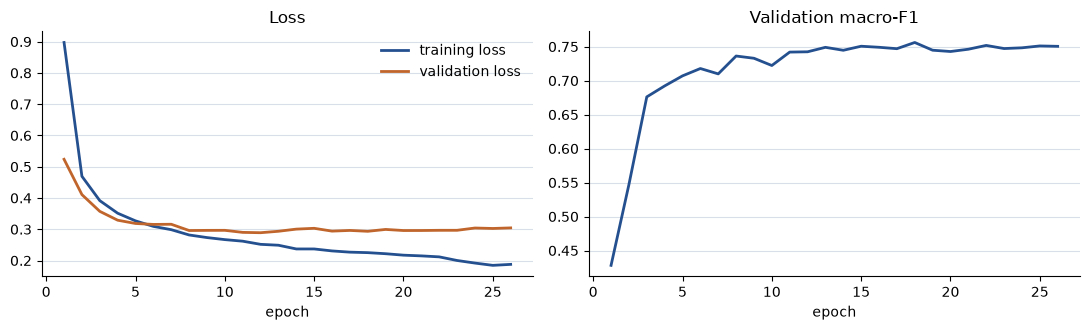

stopped after 26 epochs · best epoch 18 · val macro-F1 0.756


In [4]:
from app.ml.train import train_model
model, enc, history = train_model(X, y, train_idx, val_idx, TRAIN, verbose=False)
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(h.epoch, h.train_loss, color=NAVY, lw=2, label="training loss")
ax[0].plot(h.epoch, h.val_loss, color=RUST, lw=2, label="validation loss")
ax[0].set_xlabel("epoch"); ax[0].set_title("Loss"); ax[0].legend(frameon=False)
ax[1].plot(h.epoch, h.val_macro_f1, color=NAVY, lw=2); ax[1].set_xlabel("epoch"); ax[1].set_title("Validation macro-F1")
for a in ax: a.spines[["top", "right"]].set_visible(False); a.grid(axis="y", color="#D9DFE8")
plt.tight_layout(); plt.show()
best = h.loc[h.val_macro_f1.idxmax()]
print(f"stopped after {len(h)} epochs · best epoch {int(best.epoch)} · val macro-F1 {best.val_macro_f1:.3f}")

## 4 · Evaluation on the untouched test split

Macro-F1 is the headline metric because it weights the small categories (Meeting, Classroom, Teaching Lab) as much as the
large ones. Two baselines run on the identical split: majority class and multinomial logistic regression.

,accuracy,macro_f1
SpaceFunctionNet,0.906,0.744
majority_class,0.325,0.041
logistic_regression,0.890,0.704


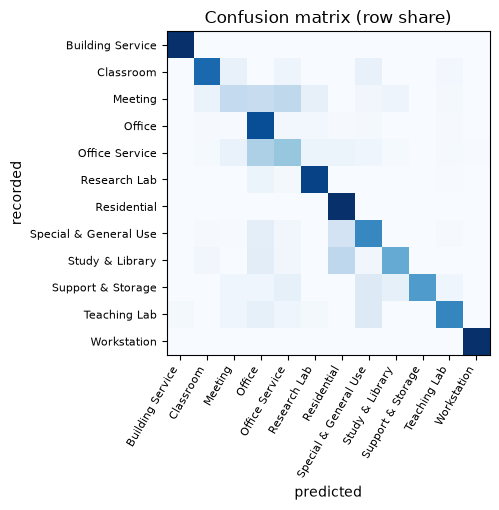

,precision,recall,f1-score,support
Building Service,1.00,1.00,1.00,1092.0
Workstation,1.00,1.00,1.00,280.0
Residential,0.94,0.99,0.97,810.0
Research Lab,0.84,0.93,0.88,176.0
Office,0.82,0.88,0.85,488.0
Classroom,0.71,0.78,0.74,41.0
Support & Storage,1.00,0.58,0.74,24.0
Special & General Use,0.78,0.66,0.72,181.0
Teaching Lab,0.71,0.67,0.69,48.0
Study & Library,0.65,0.52,0.58,29.0


In [5]:
from app.ml.train import baselines, evaluate
test = evaluate(model, enc, X, y, test_idx)
base = baselines(X, y, train_idx, test_idx, TRAIN)
summary = pd.DataFrame({"SpaceFunctionNet": {"accuracy": test["accuracy"], "macro_f1": test["macro_f1"]},
                        **{k: v for k, v in base.items()}}).T.round(3)
display(summary)
per_class = pd.DataFrame(test["per_class"]).T.loc[enc.classes, ["precision", "recall", "f1-score", "support"]].round(2)
cm = np.array(test["confusion"]); cm_norm = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.2, 5.2))
ax.imshow(cm_norm, cmap="Blues"); ax.set_xticks(range(12), enc.classes, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(12), enc.classes, fontsize=8); ax.set_xlabel("predicted"); ax.set_ylabel("recorded")
ax.set_title("Confusion matrix (row share)"); plt.tight_layout(); plt.show()
per_class.sort_values("f1-score", ascending=False)

**Interpretation.** The network beats logistic regression on macro-F1 and is far above the majority baseline. It is strong on
categories with a distinctive profile (Workstation, Residential, Building Service, Research Lab) and weak on Meeting and Office
Service, which share buildings, sizes and departments with offices. `python -m app.ml.train` also reports a harder check,
holding out entire buildings: macro-F1 falls below 0.5, so the model should only be used on buildings it has seen
(which is how the agents use it).
Those numbers are in `models/metrics.json` and on the app's **Model** page.

In [6]:
from app.ml.train import predict_proba
proba = predict_proba(model, enc, X.iloc[test_idx])
pred = np.array(enc.classes)[proba.argmax(1)]
examples = pd.DataFrame({"room": spaces.space_id.iloc[test_idx].values, "recorded": y.iloc[test_idx].values,
                         "predicted": pred, "confidence": proba.max(1).round(3)})
disagree = examples[(examples.recorded != examples.predicted) & (examples.confidence >= 0.7)]
print(f"{len(disagree)} of {len(examples):,} test records disagree with ≥70% confidence → candidates for actual-use verification")
pd.concat([examples.sample(4, random_state=3), disagree.sort_values("confidence", ascending=False).head(6)])

141 of 3,362 test records disagree with ≥70% confidence → candidates for actual-use verification


,room,recorded,predicted,confidence
2633,Moody Center · 01 · MT-A,Building Service,Building Service,1.000
437,Sid Richardson College · 06 · CH-1,Building Service,Building Service,1.000
536,Student Center · B · DW-A,Building Service,Building Service,1.000
991,BRC · 09 · 921,Research Lab,Office,0.288
2752,Ion · 04 · 425,Office Service,Office,1.000
146,Central Plant · 01 · 150F,Support & Storage,Office,0.999
77,Herzstein · B · B24,Teaching Lab,Building Service,0.999
743,Graduate Apartments · 01 · 100E,Office Service,Residential,0.997
2169,Duncan College · 01 · T-C,Office Service,Residential,0.997
1390,Space Science · 02 · HALL-B,Office Service,Research Lab,0.995


## 5 · Ablation study: which design choices matter?

`python -m app.ml.ablation` retrains the network with **one change at a time**, three seeds each, on the same split. We choose
the configuration by **validation** macro-F1 only; test scores are reported but never used to choose (that would leak the test
set into model selection). Results are saved in `models/ablation.json`; the run takes about 8 minutes, so we load them here.

,val macro-F1,val ±,test macro-F1,test ±,parameters
label,,,,,
"One-hot and no class weighting (selected, deployed)",0.7605,0.0036,0.7467,0.0039,49484
Without class weighting,0.7550,0.0032,0.7431,0.0058,23454
One-hot instead of embeddings,0.7549,0.0024,0.7489,0.0070,49484
Three hidden layers (256-128-64),0.7462,0.0009,0.7338,0.0082,66462
One hidden layer (64),0.7446,0.0025,0.7378,0.0048,10142
Original design: embeddings + class weights,0.7417,0.0042,0.7295,0.0052,23454
Without occupant features,0.7413,0.0023,0.7143,0.0054,22558
Without room-number features,0.7140,0.0062,0.7057,0.0054,19516
Without departmental allocation,0.6348,0.0016,0.6393,0.0084,19374


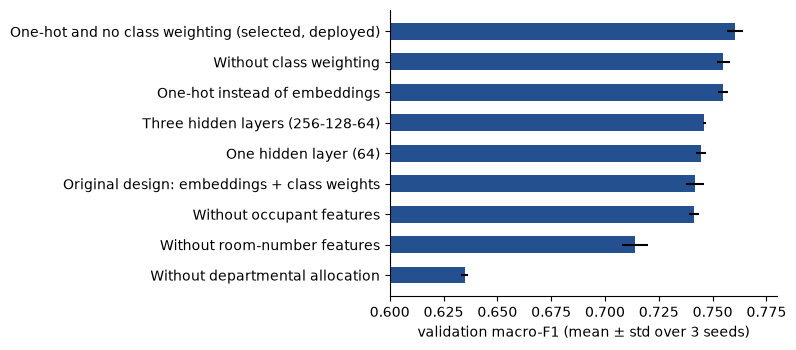

selected by validation: one_hot_no_class_weights | deployed config: use_embeddings = False class_weighting = False


In [7]:
import json
abl = json.loads((ROOT / "models" / "ablation.json").read_text())
t = pd.DataFrame(abl["variants"]).set_index("label")[["val_macro_f1", "val_std", "macro_f1", "test_std", "parameters"]]
t.columns = ["val macro-F1", "val ±", "test macro-F1", "test ±", "parameters"]
display(t.sort_values("val macro-F1", ascending=False).round(4))
order = t.sort_values("val macro-F1")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(order.index, order["val macro-F1"], xerr=order["val ±"], color=NAVY, height=0.55)
ax.set_xlim(0.6, 0.78); ax.set_xlabel("validation macro-F1 (mean ± std over 3 seeds)")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()
print("selected by validation:", abl["selected_by_validation"], "| deployed config: use_embeddings =", TRAIN.use_embeddings,
      "class_weighting =", TRAIN.class_weighting)

**What the ablation teaches us.** The *data* matters more than the architecture: removing departmental allocation costs about
0.1 macro-F1 and removing room-number features about 0.03, while depth changes almost nothing. Learned embeddings did not beat
one-hot inputs on this tabular data (each category has enough examples for one-hot weights to be learned directly), and class
weighting hurt slightly. Both findings changed the deployed model.

## 6 · Saving, loading and integration

`python -m app.ml.train` saves the deployed artifacts to `models/` (weights, encoder, metrics) and also writes **out-of-fold
predictions** from 5-fold cross-fitting, so every record shown to the agents was scored by a model that never saw its label.

At start-up the application loads them through `SpacePredictor` (`app/ml/inference.py`). Below we save this notebook's model
to a scratch folder, reload the production model, and confirm both give the same predictions (same code, same seed).

In [8]:
from app.config import MODEL_DIR
from app.ml.inference import SpacePredictor
scratch = ROOT / "models" / "notebook_run"; scratch.mkdir(exist_ok=True)
torch.save(model.state_dict(), scratch / "space_function_net.pt")
predictor = SpacePredictor(spaces)                         # what the app loads at start-up
deployed = predictor.predict_frame(spaces.iloc[test_idx[:500]]).to_numpy()
same = np.allclose(deployed, proba[:500], atol=1e-5)
print("production artifacts:", sorted(p.name for p in MODEL_DIR.glob("*.*")))
print("notebook model reproduces deployed predictions:", same)
sid = disagree.room.iloc[0]
print("\nWhat an agent tool receives for", sid); predictor.assessment(sid)

production artifacts: ['ablation.json', 'encoder.json', 'metrics.json', 'oof_predictions.csv', 'space_function_net.pt']
notebook model reproduces deployed predictions: True

What an agent tool receives for Keck · 01 · 126A


{'status': 'success',
 'recorded_group': 'Office',
 'predicted_group': 'Research Lab',
 'confidence': 0.93,
 'p_recorded': 0.065,
 'p_lab': 0.93,
 'verify_flag': True,
 'top3': [{'group': 'Research Lab', 'p': 0.93},
  {'group': 'Office', 'p': 0.065},
  {'group': 'Office Service', 'p': 0.002}]}